In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style({"font.family": "serif", "font.serif": ["Times New Roman"]})

palette = sns.color_palette("muted")
colors = {
    "tone55": palette[0],
    "tone35": palette[1],
    "tone51": palette[2],
    "tone33": palette[3],
    "tone21": palette[4],
}
labels = {
    "tone35": "35",
    "tone51": "51",
    "tone55": "55",
    "tone21": "21",
    "tone33": "33",
}

# Load the data
df = pd.read_csv("../concatenated_data/experiment3_acceptance_slope.csv")

In [19]:
languages = []
for lang, bilingual in zip(df["lang"], df["bilingual"]):
    if bilingual and lang=="man":
        languages.append(f"TM (bilingual)")
    else:
        if lang=="man":
            languages.append(f"TM (monolingual)")
        else:
            languages.append(f"TSM")

df["lang"] = languages
df["tone"] = df["tone"].apply(lambda x: {"tone51": "Falling (51) tone", "tone21": "Low (21) tone"}[x])

df["tone"] = pd.Categorical(df["tone"], categories=["Low (21) tone", "Falling (51) tone"], ordered=True)
df = df.sort_values("tone")

df["lang"] = pd.Categorical(df["lang"], categories=["TM (monolingual)", "TM (bilingual)", "TSM"], ordered=True)
df = df.sort_values(by=["lang", "tone"])

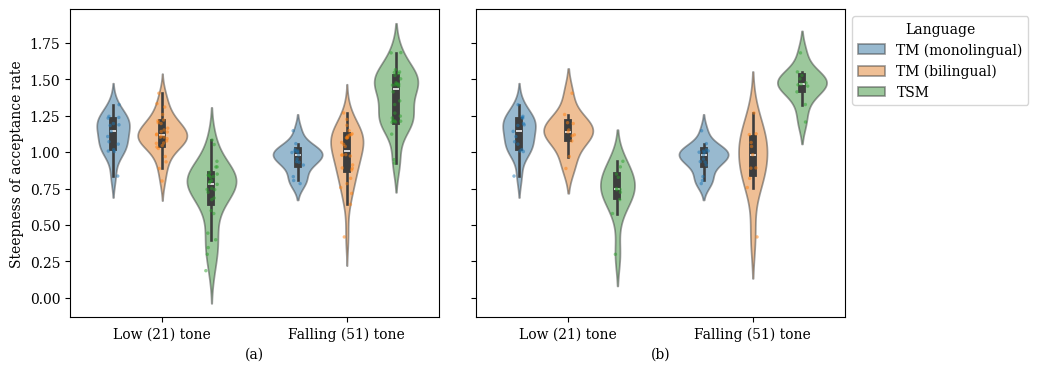

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

sns.violinplot(
    ax=axes[0],
    data=df,
    x="tone",
    y="acceptance_slope",
    hue="lang",
    alpha=0.5,
    legend=False
    )

sns.stripplot(data=df,
    x="tone",
    y="acceptance_slope",
    hue="lang",
    alpha=0.5,
    s=2.5,
    jitter=True,
    dodge=True,
    ax=axes[0],
    legend=False)

sns.violinplot(
    ax=axes[1],
    data=df[(df["lang"] == "TM (monolingual)")|(df["advanced"]==True)],
    x="tone",
    y="acceptance_slope",
    hue="lang",
    alpha=0.5,
    )

sns.stripplot(data=df[(df["lang"] == "TM (monolingual)")|(df["advanced"]==True)],
    x="tone",
    y="acceptance_slope",
    hue="lang",
    alpha=0.5,
    s=2.5,
    jitter=True,
    dodge=True,
    ax=axes[1],
    legend=False)


axes[0].set_xlabel("(a)")
axes[1].set_xlabel("(b)")
axes[0].set_ylabel("Steepness of acceptance rate")
plt.legend(title="Language", loc="upper left", bbox_to_anchor=(1, 1))
plt.subplots_adjust(wspace=0.1, hspace=0.)
plt.savefig("acceptance_slope.png", bbox_inches="tight", dpi=300)

In [21]:
# Load the data
df = pd.read_csv("../concatenated_data/experiment3_acceptance_threshold.csv")
languages = []
for lang, bilingual in zip(df["lang"], df["bilingual"]):
    if bilingual and lang=="man":
        languages.append(f"TM (bilingual)")
    else:
        if lang=="man":
            languages.append(f"TM (monolingual)")
        else:
            languages.append(f"TSM")

df["lang"] = languages
df["tone"] = df["tone"].apply(lambda x: {"tone51": "Falling (51) tone", "tone21": "Low (21) tone"}[x])

df["tone"] = pd.Categorical(df["tone"], categories=["Low (21) tone", "Falling (51) tone"], ordered=True)
df = df.sort_values("tone")

df["lang"] = pd.Categorical(df["lang"], categories=["TM (monolingual)", "TM (bilingual)", "TSM"], ordered=True)
df = df.sort_values(by=["lang", "tone"])

inverted_acceptance_thresholds = []

for tone, acceptance_threshold in zip(df["tone"], df["acceptance_threshold"]):
    if tone == "Falling (51) tone":
        inverted_acceptance_thresholds.append(acceptance_threshold)
    else:
        inverted_acceptance_thresholds.append((acceptance_threshold-11)*-1)
df["acceptance_threshold"] = inverted_acceptance_thresholds

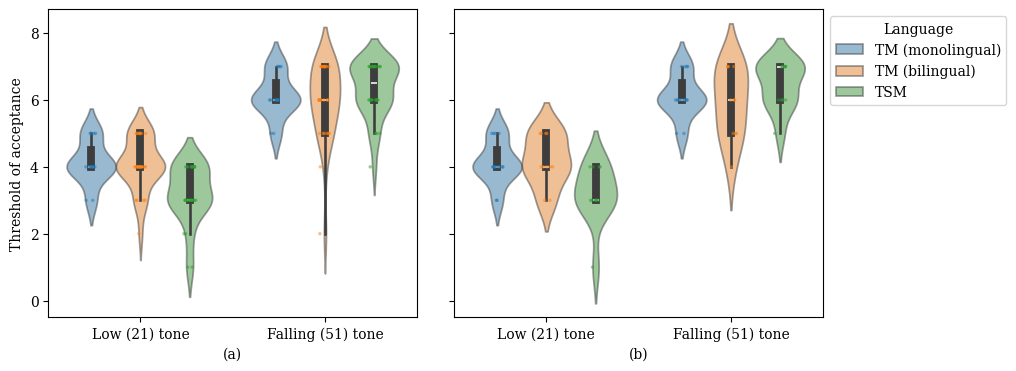

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

sns.violinplot(
    ax=axes[0],
    data=df,
    x="tone",
    y="acceptance_threshold",
    hue="lang",
    alpha=0.5,
    legend=False
    )

sns.stripplot(data=df,
    x="tone",
    y="acceptance_threshold",
    hue="lang",
    alpha=0.5,
    s=2.5,
    jitter=True,
    dodge=True,
    ax=axes[0],
    legend=False)

sns.violinplot(
    ax=axes[1],
    data=df[(df["lang"] == "TM (monolingual)")|(df["advanced"]==True)],
    x="tone",
    y="acceptance_threshold",
    hue="lang",
    alpha=0.5,
    )

sns.stripplot(data=df[(df["lang"] == "TM (monolingual)")|(df["advanced"]==True)],
    x="tone",
    y="acceptance_threshold",
    hue="lang",
    alpha=0.5,
    s=2.5,
    jitter=True,
    dodge=True,
    ax=axes[1],
    legend=False)


axes[0].set_xlabel("(a)")
axes[1].set_xlabel("(b)")
axes[0].set_ylabel("Threshold of acceptance")
plt.legend(title="Language", loc="upper left", bbox_to_anchor=(1, 1))
plt.subplots_adjust(wspace=0.1, hspace=0.)
plt.savefig("acceptance_threshold.png", bbox_inches="tight", dpi=300)

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
slope_df = pd.read_csv("../concatenated_data/experiment3_acceptance_slope.csv")

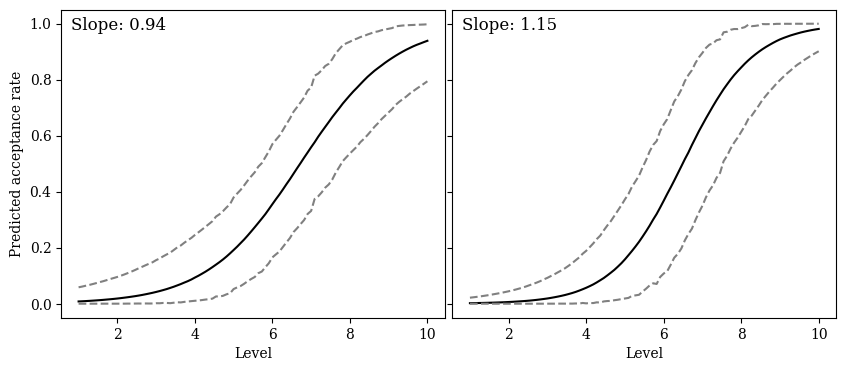

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

df = pd.read_csv("predicted_trajectories_P3_mandarin.csv")
df = df[df["tone"]=="tone51"]
sns.lineplot(data=df, x="level", y="prob", color="black", legend=False, ax=axes[0])
sns.lineplot(data=df, x="level", y="lower.HPD", color="gray", legend=False, ls="--", ax=axes[0])
sns.lineplot(data=df, x="level", y="upper.HPD", color="gray", legend=False, ls="--", ax=axes[0])
slope = slope_df[(slope_df["participant"] == "P3") & (slope_df["tone"]=="tone51")]["acceptance_slope"].values[0]
axes[0].text(0.15, .95, f"Slope: {slope:.2f}", transform=axes[0].transAxes, ha="center", va="center", fontsize=12)

df = pd.read_csv("predicted_trajectories_P15_mandarin.csv")
df = df[df["tone"]=="tone51"]
sns.lineplot(data=df, x="level", y="prob", color="black", legend=False, ax=axes[1])
sns.lineplot(data=df, x="level", y="lower.HPD", color="gray", legend=False, ls="--", ax=axes[1])
sns.lineplot(data=df, x="level", y="upper.HPD", color="gray", legend=False, ls="--", ax=axes[1])
slope = slope_df[(slope_df["participant"] == "P15") & (slope_df["tone"]=="tone51")]["acceptance_slope"].values[0]
axes[1].text(0.15, .95, f"Slope: {slope:.2f}", transform=axes[1].transAxes, ha="center", va="center", fontsize=12)

axes[0].set_xlabel("Level")
axes[1].set_xlabel("Level")
axes[0].set_ylabel("Predicted acceptance rate")

plt.subplots_adjust(wspace=0.02, hspace=0.)
plt.savefig("experiment3_logistic_regression_example.png", bbox_inches="tight", dpi=300)